# M03-1 | observer 為什麼出現在那個位置：標籤、Quantizer、prepare_pt2e

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m03_quantizer_api/01_annotate_then_prepare.ipynb)

M02 手插 observer 時，位置是直接照 XNNPACKQuantizer 抄的。這一章回答：`prepare_pt2e` 插 observer 的位置是誰決定的？

一句話的答案：**有人在那個位置貼了標籤，`prepare_pt2e` 只是照著標籤插 observer。**

這件事牽涉三個角色：

| 角色 | 是什麼 | 做什麼 |
|---|---|---|
| `QuantizationAnnotation` | 標籤，存在 `node.meta["quantization_annotation"]` | 記錄這個 node 的哪些輸入邊、或它的輸出要量化 |
| `Quantizer.annotate` | 貼標籤的人，由後端作者實作 | 決定哪些位置要量化、用什麼規格 |
| `prepare_pt2e` | 讀標籤的人 | 每個標籤位置插一個 observer，沒有標籤的地方什麼都不做 |

這本 notebook 不用任何現成的 quantizer，全部手寫：

- **A.** 標籤長什麼樣：親手貼兩張標籤。
- **B.** 三個角色的分工：寫一個最小的 Quantizer，標籤一張一張加，看 observer 一個一個長出來。
- **C.** 邊標籤與輸出標籤：同一個 tensor 有兩個使用者時差在哪。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m03_quantizer_api")

In [1]:
import copy

import torch

from common.graph_utils import observer_nodes
from common.models import example_inputs, get_model
from common.pt2e import (
    ANNOTATION_KEY,
    MinMaxObserver,
    QuantizationAnnotation,
    QuantizationSpec,
    Quantizer,
    export_module,
    prepare_pt2e,
    quiet,
)
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)

一份 `QuantizationSpec` 回答「這個位置要怎麼量化」：dtype、整數範圍、方案，以及用哪種 observer 收集統計。
這本 notebook 所有標籤都用同一份：

In [2]:
SPEC = QuantizationSpec(
    dtype=torch.int8,
    quant_min=-128,
    quant_max=127,
    qscheme=torch.per_tensor_affine,
    observer_or_fake_quant_ctr=MinMaxObserver,
)

## A. 標籤長什麼樣

`QuantizationAnnotation` 有兩個欄位，分別對應兩種位置：

- `input_qspec_map`：`{上游 node: spec}`。貼在 consumer 上，表示「上游 → 這個 node」這條**邊**要量化。注意 key 是上游的 producer，不是 consumer 自己。
- `output_qspec`：表示這個 node 的**輸出**要量化。

在 conv → relu 的小模型上貼兩張：`x → conv2d` 這條邊，以及 relu 的輸出。

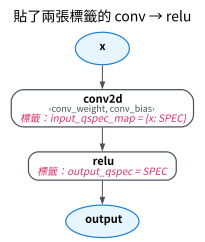

In [3]:
gm = export_module(get_model("conv_relu").eval(), example_inputs(4))
nodes = {n.name: n for n in gm.graph.nodes}  # 用名字找 node：x、conv_weight、conv2d、relu…

nodes["conv2d"].meta[ANNOTATION_KEY] = QuantizationAnnotation(input_qspec_map={nodes["x"]: SPEC})  # pyright: ignore[reportCallIssue]
nodes["relu"].meta[ANNOTATION_KEY] = QuantizationAnnotation(output_qspec=SPEC)  # pyright: ignore[reportCallIssue]

draw(gm, notes={"conv2d": "標籤：input_qspec_map = {x: SPEC}", "relu": "標籤：output_qspec = SPEC"},
     title="貼了兩張標籤的 conv → relu")

In [4]:
print(f"貼了 2 張標籤，圖上的 observer 數量 = {len(observer_nodes(gm))}")
assert len(observer_nodes(gm)) == 0

貼了 2 張標籤，圖上的 observer 數量 = 0


標籤只是寫在 `node.meta` 裡的資料，圖本身完全沒變。誰來讀它、把它變成 observer？

## B. 三個角色的分工

寫一個最小的 Quantizer：照著傳進來的清單貼標籤，不做任何判斷。`Quantizer` 只有兩個必須實作的方法：

- `annotate(model)`：貼標籤，回傳 model。
- `validate(model)`：貼完之後的檢查（這裡什麼都不檢查，用途在 M03-3）。

兩個方法被呼叫時，都記到 `calls` 裡，等一下看是誰呼叫了它們。

In [5]:
calls = []


class LabelQuantizer(Quantizer):
    def __init__(self, labels):
        self.labels = labels  # ("out", node 名稱) 或 ("edge", 上游名稱, consumer 名稱)

    def annotate(self, model):
        calls.append("annotate")
        nodes = {n.name: n for n in model.graph.nodes}
        for label in self.labels:
            if label[0] == "out":
                ann = nodes[label[1]].meta.setdefault(ANNOTATION_KEY, QuantizationAnnotation())
                ann.output_qspec = SPEC
            else:
                _, producer, consumer = label
                ann = nodes[consumer].meta.setdefault(ANNOTATION_KEY, QuantizationAnnotation())
                ann.input_qspec_map[nodes[producer]] = SPEC
        return model

    def validate(self, model):
        calls.append("validate")

從沒有標籤開始，每一步多貼一張，每一步都只呼叫 `prepare_pt2e(圖的複本, LabelQuantizer(標籤))`：

In [6]:
gm = export_module(get_model("conv_relu").eval(), example_inputs(4))
steps = [
    ("不貼標籤", []),
    ("+ relu 的輸出", [("out", "relu")]),
    ("+ 邊 x → conv2d", [("out", "relu"), ("edge", "x", "conv2d")]),
    ("+ 邊 conv_weight → conv2d", [("out", "relu"), ("edge", "x", "conv2d"), ("edge", "conv_weight", "conv2d")]),
]
prepared, rows = [], []
for title, labels in steps:
    calls.clear()
    p = prepare_pt2e(copy.deepcopy(gm), LabelQuantizer(labels))
    prepared.append((p, title))
    rows.append([title, len(labels), len(observer_nodes(p)), " → ".join(calls)])
table(rows, ["步驟", "標籤數", "observer 數", "prepare_pt2e 呼叫了"])

步驟,標籤數,observer 數,prepare_pt2e 呼叫了
不貼標籤,0,0,annotate → validate
+ relu 的輸出,1,1,annotate → validate
+ 邊 x → conv2d,2,2,annotate → validate
+ 邊 conv_weight → conv2d,3,3,annotate → validate


In [7]:
assert [r[2] for r in rows] == [0, 1, 2, 3]
assert all(r[3] == "annotate → validate" for r in rows)

- 我們從頭到尾只呼叫 `prepare_pt2e`，`annotate` 和 `validate` 是它替我們呼叫的：先貼標籤、再檢查、最後插 observer。
- 沒有標籤就沒有 observer；多一張標籤就多一個 observer。`prepare_pt2e` 自己不知道哪裡該量化，全部來自 Quantizer 貼的標籤。

完整來說，`prepare_pt2e` 依序做這幾件事（torchao 0.18 `quantize_pt2e.py`）：

1. 把 BN 折進前面的 conv（M04）。
2. 呼叫 `quantizer.transform_for_annotation(model)`：讓 Quantizer 在標註前改寫圖，例如把純量常數變成 tensor 屬性。這是選用的方法，基底類別的預設不改圖。
3. 呼叫 `quantizer.annotate(model)`：貼標籤。
4. 呼叫 `quantizer.validate(model)`：檢查標籤。
5. 照標籤插 observer：每個標籤位置依 spec 建一個 observer、插一個 `call_module` node（M02-2 手做過這個動作）。

把四個步驟的圖畫出來（第一個 row 是前兩步，第二個 row 是後兩步），綠框是這一步新長出來的 observer：

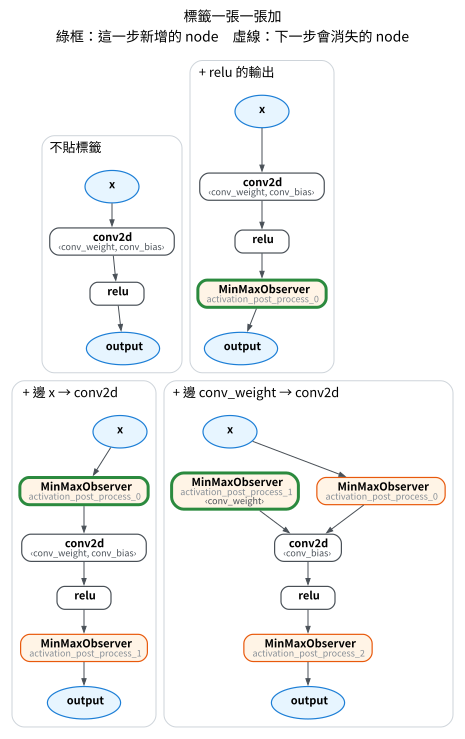

In [8]:
draw_stages(prepared, title="標籤一張一張加")

conv2d 的輸出沒有貼標籤，所以 conv2d 與 relu 之間沒有 observer。要不要在這裡量化完全由 Quantizer 決定，M04 的 fusion 就是這件事。
最後一步的三個 observer，和 M02-2 不用 Quantizer、直接改圖插的位置相同。

## C. 邊標籤與輸出標籤

換一個模型 `cat_pool`：輸入 `x` 同時餵給兩個 conv（`conv2d`、`conv2d_1`）。比較兩種標籤：

1. 只貼邊 `x → conv2d`（`input_qspec_map`）。
2. 貼 `x` 的輸出（`output_qspec`）。

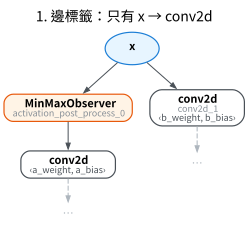

In [9]:
C_FOCUS = ["x", "activation_post_process_0", "conv2d", "conv2d_1"]  # x、observer、兩個 conv
gm_cat = export_module(get_model("cat_pool").eval(), example_inputs(4))
edge_only = prepare_pt2e(copy.deepcopy(gm_cat), LabelQuantizer([("edge", "x", "conv2d")]))
draw(edge_only, focus=C_FOCUS, hops=0, title="1. 邊標籤：只有 x → conv2d")

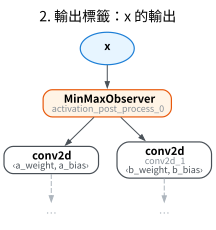

In [10]:
out_label = prepare_pt2e(copy.deepcopy(gm_cat), LabelQuantizer([("out", "x")]))
draw(out_label, focus=C_FOCUS, hops=0, title="2. 輸出標籤：x 的輸出")

In [11]:
def first_input(gm, name):
    return next(n for n in gm.graph.nodes if n.name == name).args[0]


obs_names = {n.name for n, _ in observer_nodes(edge_only)} | {n.name for n, _ in observer_nodes(out_label)}
rows = []
for label, p in [("1. 邊標籤", edge_only), ("2. 輸出標籤", out_label)]:
    for consumer in ("conv2d", "conv2d_1"):
        src = first_input(p, consumer).name
        rows.append([label, consumer, src, "量化後的 x" if src in obs_names else "原本的 x"])
table(rows, ["標籤", "consumer", "吃到的輸入", "意思"])

標籤,consumer,吃到的輸入,意思
1. 邊標籤,conv2d,activation_post_process_0,量化後的 x
1. 邊標籤,conv2d_1,x,原本的 x
2. 輸出標籤,conv2d,activation_post_process_0,量化後的 x
2. 輸出標籤,conv2d_1,activation_post_process_0,量化後的 x


In [12]:
assert [r[3] for r in rows] == ["量化後的 x", "原本的 x", "量化後的 x", "量化後的 x"]
assert first_input(out_label, "conv2d") is first_input(out_label, "conv2d_1")  # 兩個 conv 共用同一個 observer

- **邊標籤**只影響那一個 consumer：`conv2d` 吃量化後的 x，`conv2d_1` 吃原本的 x。
- **輸出標籤**影響這個 tensor 的所有 consumer：兩個 conv 共用同一個 observer。

同一個 tensor 被好幾個 op 使用時，後端可以讓其中一個吃量化值、另一個吃原值，所以標籤要能貼在「邊」上，而不只是貼在 node 上。
同一個 tensor 同時有邊標籤和輸出標籤時，不是誰覆蓋誰：兩份 spec 的屬性不同，兩個 observer 會串接（量化兩次）；
屬性完全相同才會合併成一個。這是 M03-4 的「隱式共用」。

## 小結

- 標籤（`QuantizationAnnotation`）只是 `node.meta` 裡的資料，貼了不會改圖。
- `prepare_pt2e` 先呼叫 `quantizer.annotate`、`quantizer.validate`，再照標籤插 observer。
- `input_qspec_map` 標一條邊，只影響一個 consumer；`output_qspec` 標一個輸出，影響所有 consumer。
- 手寫標籤不會推廣到別的模型。M03-2 先讀懂 XNNPACKQuantizer 貼的標籤，M03-3 改用規則（依 `node.target`）自動找 node，M03-4 處理「不同位置共用同一組 scale」。